# ガンベル誤差差分がロジスティック分布になる導出

$\varepsilon_1, \varepsilon_2 \overset{i.i.d.}{\sim} \mathrm{Gumbel}(0,1)$ のとき、

$D=\varepsilon_1-\varepsilon_2$ が標準ロジスティック分布に従うことを数式で導出する。

最後にシミュレーションで結果を確認する。


## 1. 前提

標準ガンベル分布の CDF と PDF は次である。

$$
F_\varepsilon(x)=\exp\{-e^{-x}\},\qquad
f_\varepsilon(x)=e^{-x}\exp\{-e^{-x}\}.
$$

差分を

$$
D=\varepsilon_1-\varepsilon_2
$$

と定義し、$F_D(z)=P(D\le z)$ を求める。


## 2. 分布関数を積分表示に直す

まず

$$
D=\varepsilon_1-\varepsilon_2
$$

なので、求めたい分布関数は

$$
F_D(z)=P(D\le z)=P(\varepsilon_1-\varepsilon_2\le z)
$$

である。不等式を整理すると

$$
\varepsilon_1-\varepsilon_2\le z
\iff
\varepsilon_1\le z+\varepsilon_2.
$$

したがって

$$
F_D(z)=P(\varepsilon_1\le z+\varepsilon_2).
$$

ここで全確率の公式を使い、$\varepsilon_2$ で条件づける。

$$
F_D(z)
=\int_{-\infty}^{\infty}
P(\varepsilon_1\le z+\varepsilon_2\mid \varepsilon_2=y)
 f_{\varepsilon_2}(y)\,dy.
$$

条件 $\varepsilon_2=y$ の下では、事象は

$$
\{\varepsilon_1\le z+\varepsilon_2\}
\to
\{\varepsilon_1\le z+y\}
$$

となるので

$$
F_D(z)
=\int_{-\infty}^{\infty}
P(\varepsilon_1\le z+y\mid \varepsilon_2=y)
 f_{\varepsilon_2}(y)\,dy.
$$

さらに $\varepsilon_1,\varepsilon_2$ の独立性より

$$
P(\varepsilon_1\le z+y\mid \varepsilon_2=y)
= P(\varepsilon_1\le z+y)
=F_{\varepsilon_1}(z+y).
$$

よって

$$
F_D(z)
=\int_{-\infty}^{\infty}F_{\varepsilon_1}(z+y)f_{\varepsilon_2}(y)\,dy.
$$

ここで i.i.d.（同分布）を使うと

$$
F_{\varepsilon_1}=F_{\varepsilon_2}=F_\varepsilon,
\qquad
f_{\varepsilon_2}=f_\varepsilon,
$$

したがって

$$
F_D(z)
=\int_{-\infty}^{\infty}F_\varepsilon(z+y)f_\varepsilon(y)\,dy.
$$

標準ガンベルの CDF/PDF

$$
F_\varepsilon(x)=\exp\{-e^{-x}\},
\qquad
f_\varepsilon(y)=e^{-y}\exp\{-e^{-y}\}
$$

を代入して

$$
\begin{aligned}
F_D(z)
&=\int_{-\infty}^{\infty}
\exp\{-e^{-(z+y)}\}\,e^{-y}\exp\{-e^{-y}\}\,dy\\
&=\int_{-\infty}^{\infty}
 e^{-y}\exp\{-[e^{-(z+y)}+e^{-y}]\}\,dy\\
&=\int_{-\infty}^{\infty}
 e^{-y}\exp\{-(1+e^{-z})e^{-y}\}\,dy.
\end{aligned}
$$


## 3. 変数変換を最後まで追う

前節の結果

$$
F_D(z)=\int_{-\infty}^{\infty}
 e^{-y}\exp\{-(1+e^{-z})e^{-y}\}\,dy
$$

に対して、

$$
t=e^{-y}
$$

と置く。すると

$$
\frac{dt}{dy}=-e^{-y}=-t
\quad\Rightarrow\quad
 dy=-\frac{dt}{t}.
$$

また積分区間は

$$
y\to-\infty \Rightarrow t=e^{-y}\to\infty,
\qquad
y\to\infty \Rightarrow t=e^{-y}\to0.
$$

これを代入すると

$$
\begin{aligned}
F_D(z)
&=\int_{\infty}^{0}
 t\exp\{-(1+e^{-z})t\}\left(-\frac{dt}{t}\right)\\
&=\int_{\infty}^{0}
 -\exp\{-(1+e^{-z})t\}\,dt\\
&=\int_{0}^{\infty}
 \exp\{-(1+e^{-z})t\}\,dt.
\end{aligned}
$$

ここで

$$
a=1+e^{-z}>0
$$

とおくと

$$
\int_0^{\infty}e^{-at}dt
=\left[-\frac{1}{a}e^{-at}\right]_{0}^{\infty}
=0-\left(-\frac{1}{a}\right)
=\frac{1}{a}.
$$

したがって

$$
F_D(z)=\frac{1}{1+e^{-z}}.
$$

これは標準ロジスティック分布の CDF

$$
\Lambda(z)=\frac{1}{1+e^{-z}}
$$

そのものである。ゆえに

$$
D=\varepsilon_1-\varepsilon_2\sim\mathrm{Logistic}(0,1)
$$

が示された。

密度関数も微分で確認できる。

$$
f_D(z)=\frac{d}{dz}\left(\frac{1}{1+e^{-z}}\right)
=\frac{e^{-z}}{(1+e^{-z})^2},
$$

これも標準ロジスティックの PDF である。


## 4. ロジット式への接続

効用を $U_j=V_j+\varepsilon_j$ とすると、2択で

$$
P(U_j\ge U_k)
=P(\varepsilon_k-\varepsilon_j\le V_j-V_k)
=\frac{1}{1+\exp\{-(V_j-V_k)\}}.
$$

この形がロジットモデルの基本式である。


In [3]:
# シミュレーションで D = e1 - e2 の分布を確認
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)
n = 200_000

# numpy の gumbel は location=0, scale=1 で標準ガンベル
e1 = rng.gumbel(loc=0.0, scale=1.0, size=n)
e2 = rng.gumbel(loc=0.0, scale=1.0, size=n)
d = e1 - e2

# logistic(0,1) との KS 検定
ks_stat, p_value = stats.kstest(d, "logistic", args=(0, 1))
print(f"KS statistic = {ks_stat:.6f}")
print(f"p-value      = {p_value:.6f}")
print(f"sample mean  = {d.mean():.6f} (theory: 0)")
print(f"sample var   = {d.var():.6f} (theory: pi^2/3 = {np.pi**2 / 3:.6f})")

KS statistic = 0.002068
p-value      = 0.358705
sample mean  = -0.000083 (theory: 0)
sample var   = 3.276423 (theory: pi^2/3 = 3.289868)


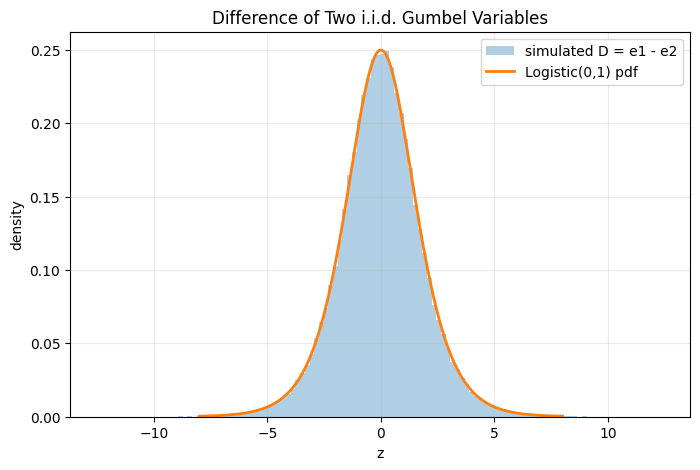

In [4]:
# ヒストグラムと理論密度の比較
x = np.linspace(-8, 8, 600)
pdf_theory = stats.logistic.pdf(x, loc=0, scale=1)

plt.figure(figsize=(8, 5))
plt.hist(d, bins=120, density=True, alpha=0.35, label="simulated D = e1 - e2")
plt.plot(x, pdf_theory, linewidth=2.0, label="Logistic(0,1) pdf")
plt.title("Difference of Two i.i.d. Gumbel Variables")
plt.xlabel("z")
plt.ylabel("density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()